# Phase 2 — DTSP and EEG signal analysis

This notebook applies Digital Signal Processing to the data. **Every waveform-based cell is gated** on the Phase 1 verdict:
it only runs if the row structure was verified as a waveform (`blocks` or `single_sequence`). Otherwise it prints why it was skipped
and only the order-independent amplitude analysis (section 2) runs.

Frequencies are in **normalised units (cycles/sample, 0-0.5)** unless a sampling rate was explicitly assumed in Phase 1.
A normalised frequency `f` corresponds to `f · fs` Hz for whatever `fs` really is.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy import signal as sp, stats
from eeg_signal_classification import data_loader as dl, feature_extraction as fe, preprocessing as pp
from eeg_signal_classification import signal_analysis as sa
from eeg_signal_classification.utils import RESULTS_DIR, load_structure, set_seed

set_seed(); sns.set_theme(style="whitegrid"); FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
structure = load_structure()
LAYOUT, FS_HZ = structure["layout"], structure["fs_hz"]
FS, UNIT = sa.effective_fs(FS_HZ), sa.freq_unit(FS_HZ)
WAVEFORM_OK = LAYOUT in ("blocks", "single_sequence")
N_BLOCKS, BLOCK_LEN = structure["n_blocks"], structure["block_length"]
signals, labels = dl.open_signals(), dl.load_labels()
y = (labels == structure["seizure_label"]).astype(int)
NAMES = {0: "non-seizure", 1: "seizure"}; COLORS = {0: "tab:blue", 1: "tab:red"}
print(f"layout = {LAYOUT} | blocks = {N_BLOCKS} x {BLOCK_LEN} | frequency unit = {UNIT} | fs status: {structure['fs_status']}")
print("waveform analysis enabled:", WAVEFORM_OK)

layout = blocks | blocks = 18 x 2048 | frequency unit = cycles/sample | fs status: unknown - analysis in normalised frequency
waveform analysis enabled: True


## 1. Draw the analysis subset

Up to 300 random rows per class (fixed seed). All analyses below use these rows; `blocks_*` arrays have shape
*(rows, blocks, samples per block)*.

In [2]:
if WAVEFORM_OK:
    rng = np.random.default_rng(42)
    idx = {c: np.sort(rng.choice(np.flatnonzero(y == c), size=min(300, int((y == c).sum())), replace=False)) for c in (0, 1)}
    blocks = {c: np.asarray(signals[idx[c]], dtype=np.float64).reshape(len(idx[c]), N_BLOCKS, BLOCK_LEN) for c in (0, 1)}
    time_axis = np.arange(BLOCK_LEN) / FS if FS_HZ else np.arange(BLOCK_LEN)
    TIME_LABEL = "time (s) [assumed fs]" if FS_HZ else "sample index"
    print({NAMES[c]: blocks[c].shape for c in blocks})
else:
    print('Skipped: waveform structure not verified in Phase 1.')

{'non-seizure': (300, 18, 2048), 'seizure': (300, 18, 2048)}


## 2. Amplitude statistics (valid for any column order)

For a segment `x[n]`, `n = 0..N-1`: mean `μ = (1/N)Σx`, variance `σ² = (1/N)Σ(x−μ)²`, standard deviation `σ`,
RMS `= sqrt((1/N)Σx²)`, peak-to-peak `= max − min`. Seizure activity is often higher-amplitude and more rhythmic,
which should show up as larger `σ`/RMS/peak-to-peak. **Caveat:** the data are column-standardised, so absolute microvolt
amplitudes are gone; only amplitudes *relative to the dataset* remain.

class,non-seizure,seizure
row-level statistic (median),,
mean,-0.000208,-0.000623
std,0.479160,1.227397
var,0.229594,1.506511
rms,0.479215,1.227399
energy,8465.693456,55536.192505
ptp,7.493500,16.601500
skew,0.010026,0.030731
kurtosis,4.506052,1.957274


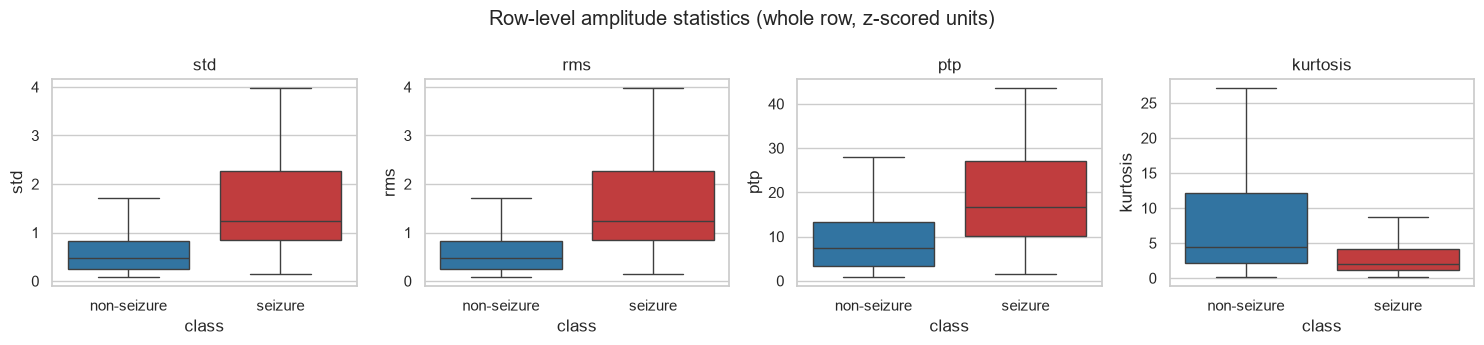

std       Mann-Whitney U p-value = 7.81e-104
rms       Mann-Whitney U p-value = 7.69e-104
ptp       Mann-Whitney U p-value = 2.24e-68
kurtosis  Mann-Whitney U p-value = 5.58e-43


In [3]:
rows_stat = np.sort(np.random.default_rng(0).choice(len(y), size=min(3000, len(y)), replace=False))
row_stats = pd.DataFrame(fe.statistical_features(np.asarray(signals[rows_stat], dtype=np.float64)))
row_stats["class"] = pd.Series(y[rows_stat]).map(NAMES).to_numpy()
display(row_stats.groupby("class").median().T.rename_axis("row-level statistic (median)"))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, ["std", "rms", "ptp", "kurtosis"]):
    sns.boxplot(data=row_stats, x="class", y=col, ax=ax, showfliers=False, palette=["tab:blue", "tab:red"], hue="class", legend=False)
    ax.set_title(col)
fig.suptitle("Row-level amplitude statistics (whole row, z-scored units)"); fig.tight_layout()
fig.savefig(FIG / "02_amplitude_stats.png", dpi=150); plt.show()
for col in ["std", "rms", "ptp", "kurtosis"]:
    u = stats.mannwhitneyu(row_stats.loc[row_stats["class"] == "seizure", col], row_stats.loc[row_stats["class"] == "non-seizure", col])
    print(f"{col:9s} Mann-Whitney U p-value = {u.pvalue:.2e}")

## 3. Time-domain visualisation

One random seizure row and one random non-seizure row; first two blocks of each. The x-axis is the sample index within the
block (it becomes seconds only if a sampling rate was explicitly assumed). Compare amplitude, rhythmicity and spikiness.

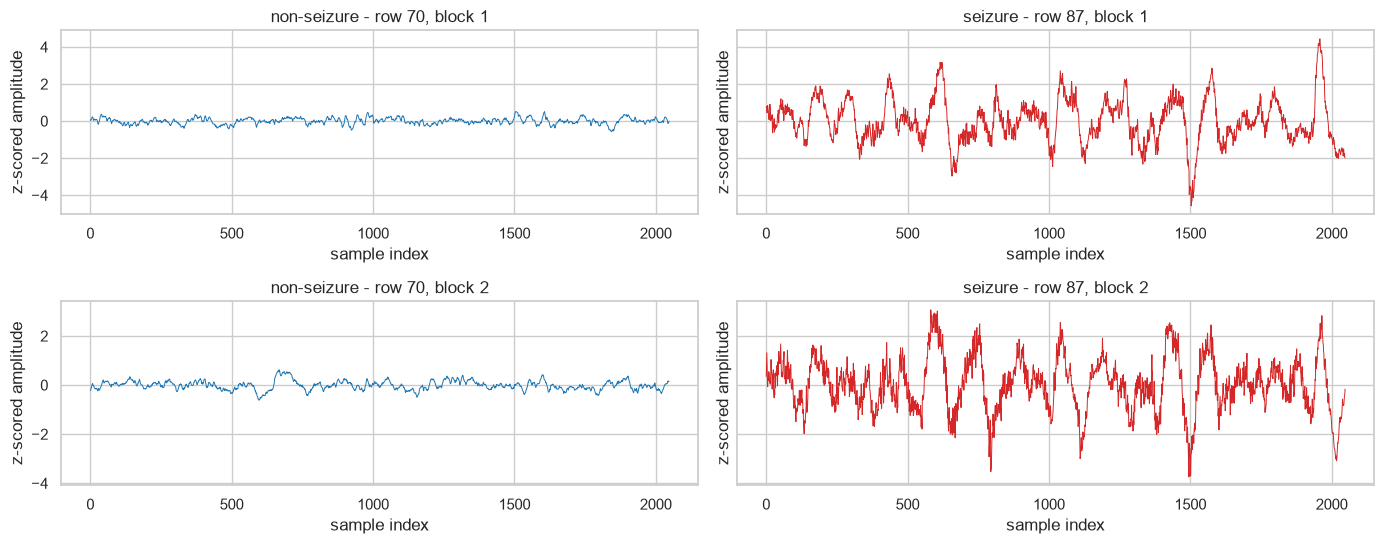

In [4]:
if WAVEFORM_OK:
    n_show = min(2, N_BLOCKS)
    fig, axes = plt.subplots(n_show, 2, figsize=(14, 2.8 * n_show), sharey="row", squeeze=False)
    for col, c in enumerate((0, 1)):
        for b in range(n_show):
            axes[b, col].plot(time_axis, blocks[c][0, b], color=COLORS[c], lw=0.7)
            axes[b, col].set(title=f"{NAMES[c]} - row {idx[c][0]}, block {b + 1}", xlabel=TIME_LABEL, ylabel="z-scored amplitude")
    fig.tight_layout(); fig.savefig(FIG / "02_time_domain.png", dpi=150); plt.show()
else:
    print('Skipped: waveform structure not verified in Phase 1.')

In [5]:
if WAVEFORM_OK:
    # Block-level time-domain statistics, averaged over the analysis rows
    table = []
    for c in (0, 1):
        s = fe.statistical_features(blocks[c])
        table.append(pd.Series({k: float(np.mean(v)) for k, v in s.items()}, name=NAMES[c]))
    display(pd.DataFrame(table).T.rename_axis("mean over rows and blocks"))
else:
    print('Skipped: waveform structure not verified in Phase 1.')

,non-seizure,seizure
mean over rows and blocks,,
mean,0.000998,-0.001006
std,0.602509,1.597474
var,0.676805,3.665430
rms,0.603500,1.598733
energy,1389.318149,7515.072000
ptp,4.721884,11.497101
skew,0.069521,0.064729
kurtosis,3.092736,1.645338


## 4. Has the data already been filtered? (check before filtering)

We estimate the average power spectrum of the data. A sharp roll-off or a dip at a mains frequency would suggest earlier
filtering. We report the share of power in the top 20 % of the frequency axis: if it is tiny, the data were probably low-passed
or are naturally very smooth, and extra filtering would add little.

{'fraction_power_top_20pct_of_band': 0.0049498581172162425}


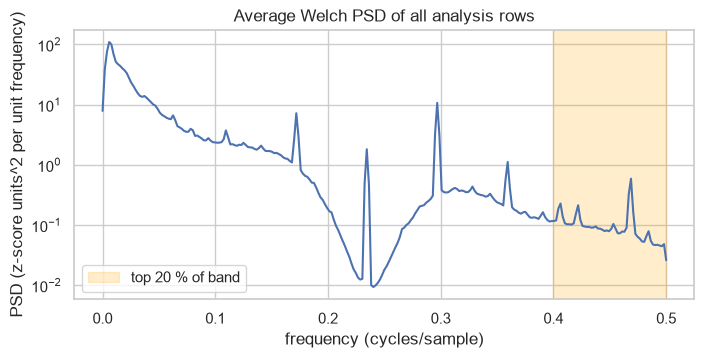

In [6]:
if WAVEFORM_OK:
    all_blocks = np.concatenate([blocks[0], blocks[1]])
    freqs, psd_all = sa.welch_psd(all_blocks, fs=FS, nperseg=min(512, BLOCK_LEN))
    mean_psd = psd_all.reshape(-1, psd_all.shape[-1]).mean(axis=0)
    check = pp.high_frequency_check(mean_psd, freqs, FS / 2)
    print(check)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.semilogy(freqs, mean_psd); ax.axvspan(0.8 * FS / 2, FS / 2, color="orange", alpha=0.2, label="top 20 % of band")
    ax.set(title="Average Welch PSD of all analysis rows", xlabel=f"frequency ({UNIT})", ylabel="PSD (z-score units^2 per unit frequency)"); ax.legend()
    fig.savefig(FIG / "02_existing_preprocessing_check.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 5. Butterworth band-pass filter (demonstration)

A Butterworth filter has a maximally flat pass-band; the magnitude response is `|H(f)|² = 1 / (1 + (f/f_c)^{2N})` for a low-pass
of order `N`. We use a 4th-order band-pass as second-order sections and apply it **forward and backward** (`sosfiltfilt`),
which gives zero phase distortion (no time shift of peaks), at the cost of doubling the effective order.

**This is a demonstration, not a preprocessing step for the classifier.** The features in Phase 3 are computed from the data as provided,
because the filtering state of the data is unknown. With an explicit fs the band is 0.5-40 Hz (a typical clinical EEG band);
without fs we use the same band expressed as fractions of the sampling rate, 0.002-0.156 cycles/sample, which equals
0.5-40 Hz **only if** fs were 256 Hz.

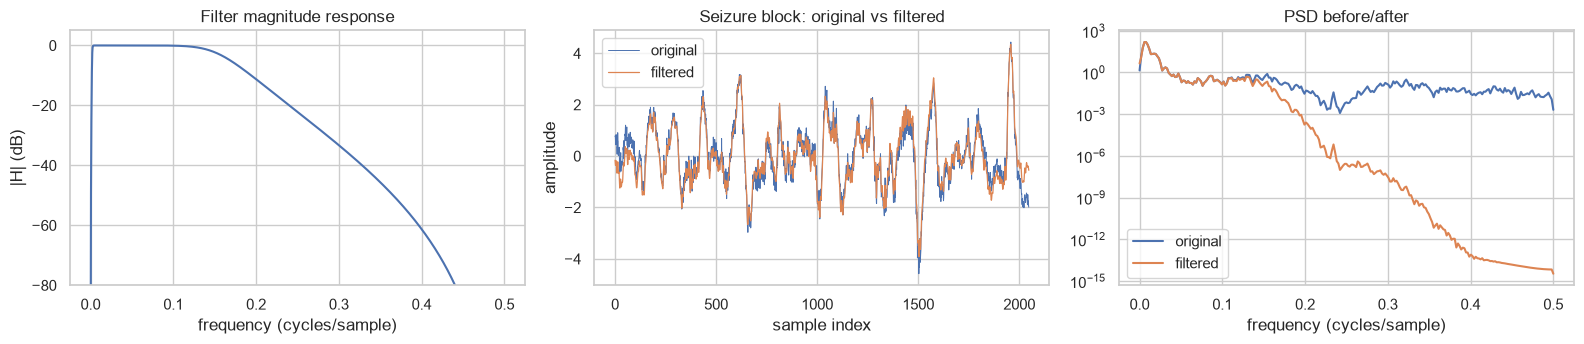

RMS original 1.202 -> filtered 1.167


In [7]:
if WAVEFORM_OK:
    low, high = (0.5, 40.0) if FS_HZ else (0.002, 0.156)
    sos = sa.butter_bandpass_sos(low, high, FS, order=4)
    w, h = sp.sosfreqz(sos, worN=4096, fs=FS)
    x = blocks[1][0, 0]
    x_filtered = sa.bandpass_filter(x, low, high, FS, order=4)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
    axes[0].plot(w, 20 * np.log10(np.maximum(np.abs(h), 1e-6))); axes[0].set(ylim=(-80, 5), title="Filter magnitude response", xlabel=f"frequency ({UNIT})", ylabel="|H| (dB)")
    axes[1].plot(time_axis, x, label="original", lw=0.7); axes[1].plot(time_axis, x_filtered, label="filtered", lw=0.9)
    axes[1].set(title="Seizure block: original vs filtered", xlabel=TIME_LABEL, ylabel="amplitude"); axes[1].legend()
    f1, p1 = sa.welch_psd(x, FS, 512); f2, p2 = sa.welch_psd(x_filtered, FS, 512)
    axes[2].semilogy(f1, p1, label="original"); axes[2].semilogy(f2, p2, label="filtered")
    axes[2].set(title="PSD before/after", xlabel=f"frequency ({UNIT})"); axes[2].legend()
    fig.tight_layout(); fig.savefig(FIG / "02_filtering.png", dpi=150); plt.show()
    print(f"RMS original {np.sqrt(np.mean(x**2)):.3f} -> filtered {np.sqrt(np.mean(x_filtered**2)):.3f}")
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 6. FFT magnitude spectrum

The DFT `X[k] = Σ x[n] e^{−j2πkn/N}` converts the segment into frequency components. We plot `|X[k]|/N` after removing the mean
(the DC term would dominate). Frequency resolution is `fs/N`; the single-segment FFT is noisy, which motivates Welch's method next.

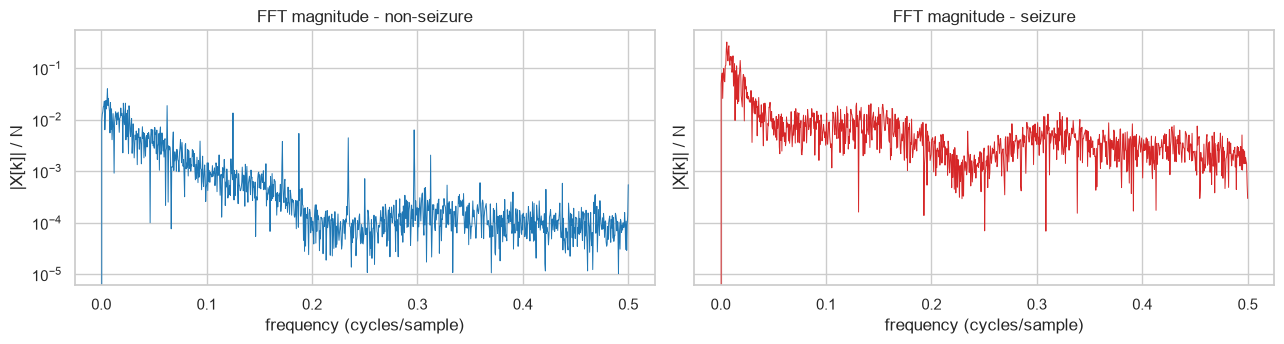

In [8]:
if WAVEFORM_OK:
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
    for ax, c in zip(axes, (0, 1)):
        f, mag = sa.fft_magnitude(blocks[c][0, 0], FS)
        ax.semilogy(f, mag, color=COLORS[c], lw=0.7); ax.set(title=f"FFT magnitude - {NAMES[c]}", xlabel=f"frequency ({UNIT})", ylabel="|X[k]| / N")
    fig.tight_layout(); fig.savefig(FIG / "02_fft.png", dpi=150); plt.show()
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 7. Power spectral density (Welch)

Welch's method splits the segment into overlapping windows, applies a Hann window, computes a periodogram of each and averages them.
This trades frequency resolution for a much lower-variance estimate. PSD units are (signal units)² per unit frequency; the
area under the PSD is the signal power.

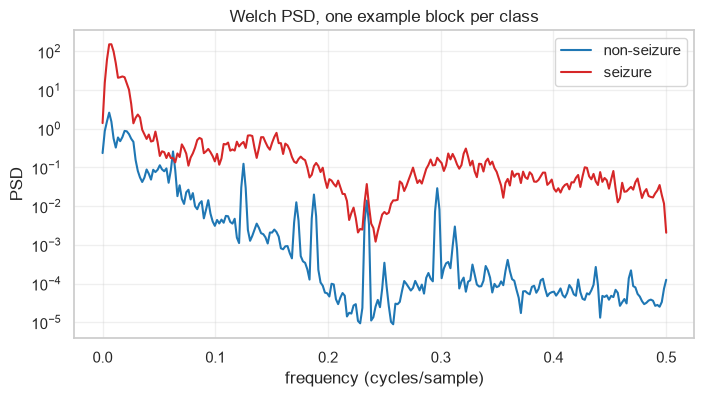

In [9]:
if WAVEFORM_OK:
    fig, ax = plt.subplots(figsize=(8, 4))
    for c in (0, 1):
        f, p = sa.welch_psd(blocks[c][0, 0], FS, 512)
        ax.semilogy(f, p, color=COLORS[c], label=NAMES[c])
    ax.set(title="Welch PSD, one example block per class", xlabel=f"frequency ({UNIT})", ylabel="PSD"); ax.legend(); ax.grid(alpha=0.3)
    fig.savefig(FIG / "02_welch_example.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 8. Band power and relative band power

Band power is the area under the PSD inside a band (trapezoid rule): `P_band = ∫_{f1}^{f2} S(f) df`. Relative band power is
`P_band / Σ P_bands`, which removes overall amplitude and shows how power is distributed over frequency.

* With **no sampling rate**: five equal-width normalised bands `nb1` (0-0.1) ... `nb5` (0.4-0.5). They have no clinical names.
* With an **assumed** sampling rate: delta 0.5-4, theta 4-8, alpha 8-13, beta 13-30, gamma 30-80 Hz (clipped at Nyquist).

We average over the blocks of each row first so that each **row** counts once in the statistical test (blocks of the same row are not independent).

{'nb1': (0.0, 0.1), 'nb2': (0.1, 0.2), 'nb3': (0.2, 0.3), 'nb4': (0.3, 0.4), 'nb5': (0.4, 0.5)}


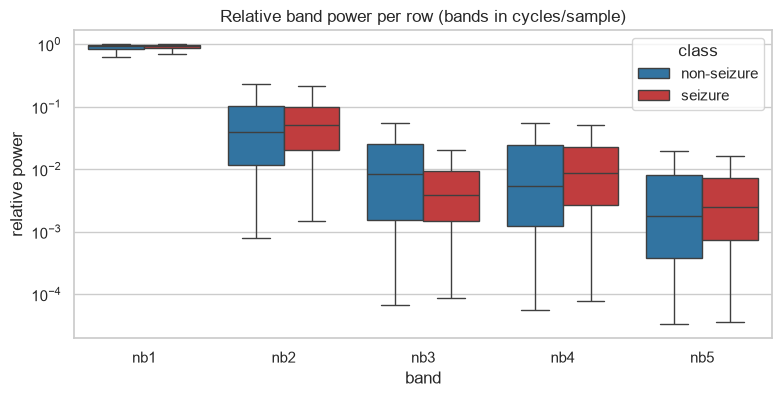

,median seizure,median non-seizure,ratio (seizure / non),Mann-Whitney p
band,,,,
nb1,0.929835,0.937351,0.991981,0.672146
nb2,0.050669,0.039131,1.294858,0.029147
nb3,0.003845,0.008491,0.452850,0.000003
nb4,0.008678,0.005372,1.615320,0.021225
nb5,0.002462,0.001789,1.376450,0.104415


In [10]:
if WAVEFORM_OK:
    bands = sa.get_bands(FS_HZ)
    print({k: tuple(round(v, 3) for v in lim) for k, lim in bands.items()})
    long_rows, row_level = [], {}
    for c in (0, 1):
        f, psd = sa.welch_psd(blocks[c], FS, 512)
        rel = sa.relative_band_power(sa.band_power(f, psd, bands))
        row_level[c] = {name: v.mean(axis=1) for name, v in rel.items()}     # one value per row
        for name, v in row_level[c].items():
            long_rows += [(NAMES[c], name, val) for val in v]
    rel_df = pd.DataFrame(long_rows, columns=["class", "band", "relative power"])
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.boxplot(data=rel_df, x="band", y="relative power", hue="class", palette=["tab:blue", "tab:red"], ax=ax, showfliers=False)
    ax.set(title=f"Relative band power per row (bands in {UNIT})", yscale="log"); fig.savefig(FIG / "02_band_power.png", dpi=150, bbox_inches="tight"); plt.show()
    tests = []
    for name in bands:
        u = stats.mannwhitneyu(row_level[1][name], row_level[0][name])
        tests.append({"band": name, "median seizure": np.median(row_level[1][name]), "median non-seizure": np.median(row_level[0][name]),
                      "ratio (seizure / non)": np.median(row_level[1][name]) / np.median(row_level[0][name]), "Mann-Whitney p": u.pvalue})
    band_table = pd.DataFrame(tests).set_index("band"); display(band_table)
    band_table.to_csv(RESULTS_DIR / "band_power_comparison.csv")
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 9. Short-Time Fourier Transform (spectrogram)

The STFT `X(m, k) = Σ x[n] w[n − mH] e^{−j2πkn/N_w}` computes the spectrum of short windows sliding along the segment, showing how the
frequency content changes in time. Window length trades time resolution against frequency resolution (we use a Hann window of
`N/4` samples with 50 % overlap). Colour is power on a log scale, shared between the two plots.

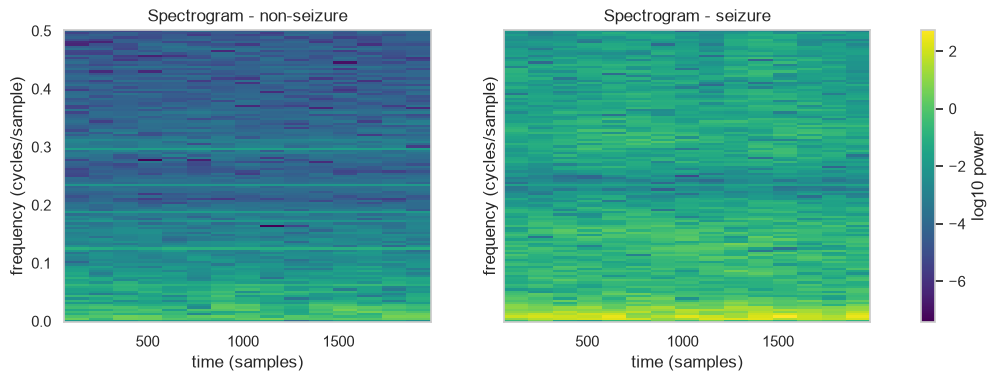

In [11]:
if WAVEFORM_OK:
    nperseg = max(64, min(256, BLOCK_LEN // 4))
    spectra = {c: sa.stft_spectrogram(blocks[c][0, 0], FS, nperseg=nperseg) for c in (0, 1)}
    vmin = min(np.log10(spectra[c][2] + 1e-12).min() for c in (0, 1)); vmax = max(np.log10(spectra[c][2] + 1e-12).max() for c in (0, 1))
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    for ax, c in zip(axes, (0, 1)):
        f, t, S = spectra[c]
        mesh = ax.pcolormesh(t, f, np.log10(S + 1e-12), shading="auto", vmin=vmin, vmax=vmax, cmap="viridis")
        ax.set(title=f"Spectrogram - {NAMES[c]}", xlabel="time (s)" if FS_HZ else "time (samples)", ylabel=f"frequency ({UNIT})")
    fig.colorbar(mesh, ax=axes, label="log10 power"); fig.savefig(FIG / "02_spectrogram.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 10. Seizure vs non-seizure: class-level spectrum

Median Welch PSD over all analysis segments of each class with the inter-quartile range as a band. Differences between the curves are what a
spectral-feature classifier can exploit. The result is saved for the final notebook.

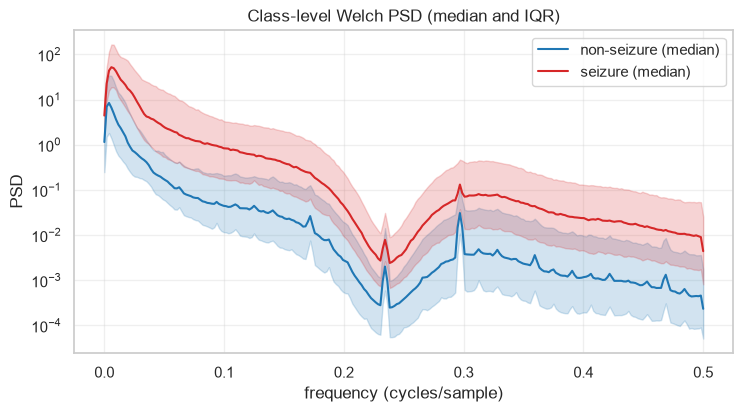

In [12]:
if WAVEFORM_OK:
    all_blocks = np.concatenate([blocks[0], blocks[1]]); all_y = np.concatenate([np.zeros(len(blocks[0]), int), np.ones(len(blocks[1]), int)])
    class_psd = sa.mean_psd_by_class(all_blocks, all_y, fs=FS, nperseg=512)
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    for c, d in class_psd.items():
        ax.semilogy(d["freqs"], d["median"], color=COLORS[c], label=f"{NAMES[c]} (median)")
        ax.fill_between(d["freqs"], d["q25"], d["q75"], color=COLORS[c], alpha=0.2)
    ax.set(title="Class-level Welch PSD (median and IQR)", xlabel=f"frequency ({UNIT})", ylabel="PSD"); ax.legend(); ax.grid(alpha=0.3)
    fig.savefig(FIG / "02_class_psd.png", dpi=150, bbox_inches="tight"); plt.show()
    np.savez(RESULTS_DIR / "class_mean_psd.npz", freqs=class_psd[0]["freqs"], unit=UNIT,
             **{f"{k}_{c}": class_psd[c][k] for c in class_psd for k in ("median", "q25", "q75")})
else:
    print('Skipped: waveform structure not verified in Phase 1.')

## 11. Observations (computed, then interpret)

The cell below prints numbers from the analysis. Read the plots and the table above, then write your own conclusions
in the presentation; the points to discuss are listed after the code.

In [13]:
if WAVEFORM_OK:
    print("Row-level amplitude: median std  seizure / non-seizure =",
          round(row_stats.loc[row_stats['class']=='seizure','std'].median() / row_stats.loc[row_stats['class']=='non-seizure','std'].median(), 3))
    top = band_table["ratio (seizure / non)"].sort_values(ascending=False)
    print("Band with the largest relative-power increase in seizure rows:", top.index[0], f"(x{top.iloc[0]:.2f})")
    print("Band with the largest relative-power decrease in seizure rows:", top.index[-1], f"(x{top.iloc[-1]:.2f})")
    print("Bands with Mann-Whitney p < 0.001:", list(band_table.index[band_table['Mann-Whitney p'] < 1e-3]))
else:
    print('Skipped: waveform structure not verified in Phase 1.')

Row-level amplitude: median std  seizure / non-seizure = 2.562
Band with the largest relative-power increase in seizure rows: nb4 (x1.62)
Band with the largest relative-power decrease in seizure rows: nb3 (x0.45)
Bands with Mann-Whitney p < 0.001: ['nb3']


**Points to discuss:** (1) does seizure power shift towards particular frequencies, (2) is the effect consistent across the IQR band
or only in the median, (3) which of these conclusions would survive a change of the (unknown) sampling rate, and (4) the statistical tests treat rows as
independent although neighbouring rows may come from the same recording, so p-values are optimistic.

**If this notebook skipped the waveform sections:** the verified information in the CSV does not support time/frequency analysis, so the project
continues with order-independent statistical features only (Phase 3).